# Análisis Exploratorio y Resultados - Laboratorio 02
**Asignatura:** Machine Learning (2026-02)  
**Integrantes:** Martín Droguett y Amelie Valderrama  
**Objetivo:** Comparación de embeddings faciales lineales (PCA, LDA y Fisherfaces) sobre Olivetti y LFW.

In [1]:
import pandas as pd
from src.datos.olivetti import CargadorOlivetti
from src.datos.lfw import CargadorLFW

# Cargar datasets
olivetti = CargadorOlivetti().cargar()
lfw = CargadorLFW().cargar()

print("=== CARACTERÍSTICAS DE LOS CONJUNTOS ===")
print(f"Olivetti -> Muestras (N): {olivetti.X.shape[0]}, Clases (C): {olivetti.n_clases}, Resolución: {olivetti.alto}x{olivetti.ancho} (píxeles: {olivetti.X.shape[1]})")
print(f"LFW      -> Muestras (N): {lfw.X.shape[0]}, Clases (C): {lfw.n_clases}, Resolución: {lfw.alto}x{lfw.ancho} (píxeles: {lfw.X.shape[1]})")

=== CARACTERÍSTICAS DE LOS CONJUNTOS ===
Olivetti -> Muestras (N): 400, Clases (C): 40, Resolución: 64x64 (píxeles: 4096)
LFW      -> Muestras (N): 2773, Clases (C): 50, Resolución: 62x47 (píxeles: 2914)


In [2]:
# Cargar resultados de los experimentos
df_res = pd.read_csv("data/resultados/resultados_modelos.csv")

print("\n--- RESUMEN EXPERIMENTAL: OLIVETTI ---")
tabla_olivetti = df_res[df_res["dataset"] == "olivetti"].pivot_table(
    index=["embedding", "d"], columns="modelo", values=["accuracy", "macro_f1"]
)
display(tabla_olivetti)

print("\n--- RESUMEN EXPERIMENTAL: LFW ---")
tabla_lfw = df_res[df_res["dataset"] == "lfw"].pivot_table(
    index=["embedding", "d"], columns="modelo", values=["accuracy", "macro_f1"]
)
display(tabla_lfw)


--- RESUMEN EXPERIMENTAL: OLIVETTI ---


accuracy              macro_f1                    
modelo            arbol   knn   svm     arbol       knn       svm
embedding   d                                                    
fisherfaces 10     0.44  0.80  0.90  0.398790  0.779524  0.896190
            20     0.37  0.95  0.98  0.293364  0.937024  0.978095
            30     0.29  0.95  0.96  0.250032  0.941429  0.959524
lda         10     0.31  0.99  0.98  0.313512  0.990000  0.980000
            20     0.30  0.97  0.97  0.297087  0.968095  0.969524
            30     0.31  0.97  0.96  0.307921  0.969524  0.957619
pca         10     0.31  0.78  0.86  0.266705  0.772679  0.851548
            20     0.36  0.83  0.95  0.340456  0.825734  0.946548
            30     0.33  0.84  0.98  0.302976  0.831190  0.979524


--- RESUMEN EXPERIMENTAL: LFW ---


accuracy                      macro_f1                    
modelo             arbol       knn       svm     arbol       knn       svm
embedding   d                                                             
fisherfaces 10  0.246398  0.216138  0.332853  0.121651  0.124279  0.176450
            20  0.311239  0.344380  0.438040  0.172499  0.258347  0.320795
            30  0.298271  0.402017  0.484150  0.160918  0.308251  0.395485
lda         10  0.119597  0.182997  0.175793  0.053752  0.095169  0.103805
            20  0.105187  0.246398  0.219020  0.039259  0.159347  0.157062
            30  0.112392  0.269452  0.243516  0.043343  0.169298  0.176892
pca         10  0.221902  0.191643  0.329971  0.065241  0.125886  0.172970
            20  0.208934  0.233429  0.440922  0.082750  0.149763  0.321716
            30  0.216138  0.272334  0.485591  0.088935  0.192730  0.383481

1. Curvas de Varianza Acumulada PCA (Olivetti y LFW):


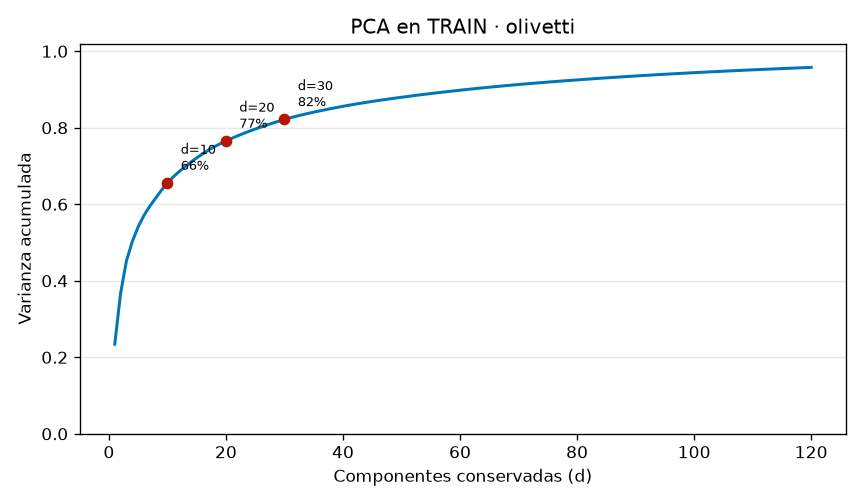

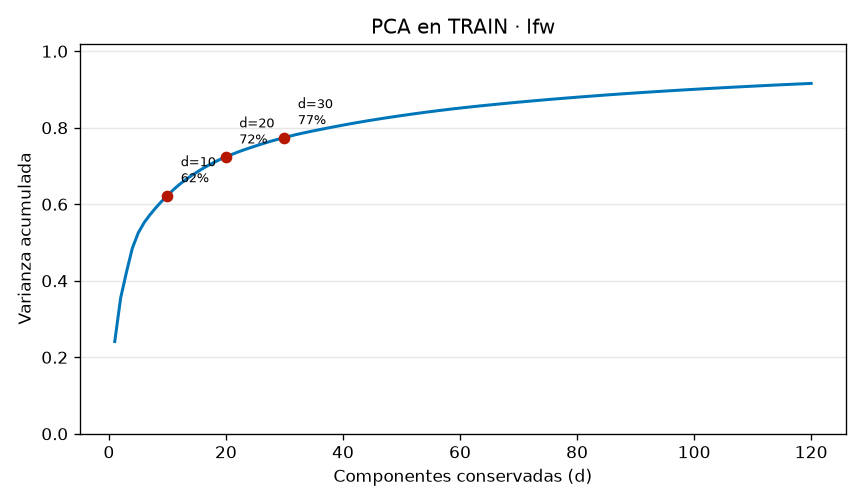

2. Mapa t-SNE Fisherfaces d=20 (Olivetti):


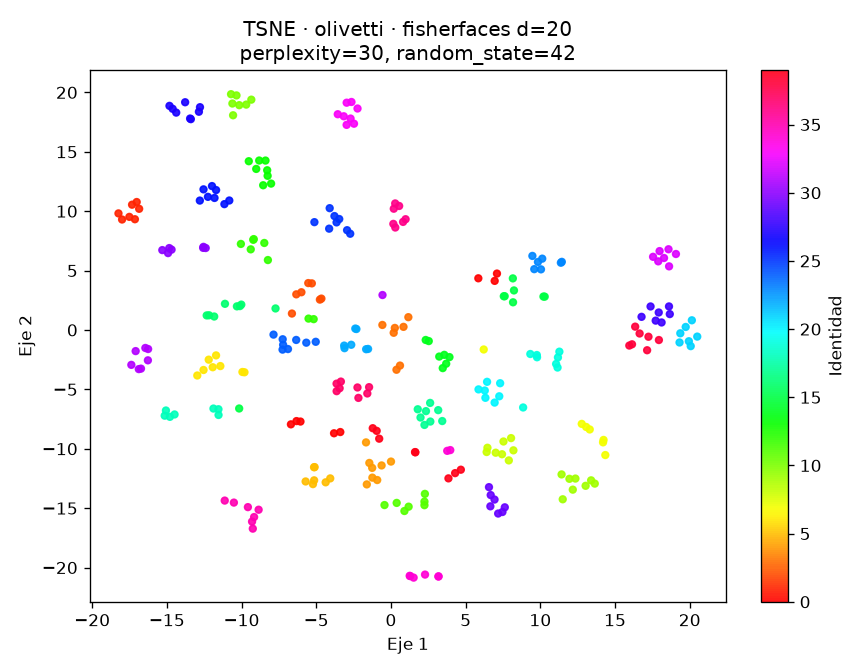

In [3]:
from IPython.display import Image, display

print("1. Curvas de Varianza Acumulada PCA (Olivetti y LFW):")
display(Image(filename="figuras/curva_pca_olivetti.png", width=600))
display(Image(filename="figuras/curva_pca_lfw.png", width=600))

print("2. Mapa t-SNE Fisherfaces d=20 (Olivetti):")
display(Image(filename="figuras/tsne_olivetti_fisherfaces_d20.png", width=600))

## Fotografías mal clasificadas en TEST
Cada columna muestra una foto de TEST mal clasificada (arriba) y una foto de TRAIN de la identidad que predijo el modelo (abajo).

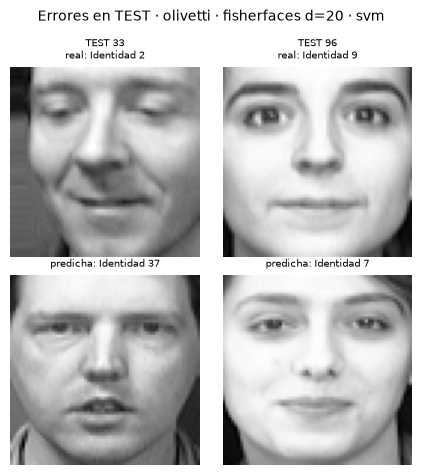

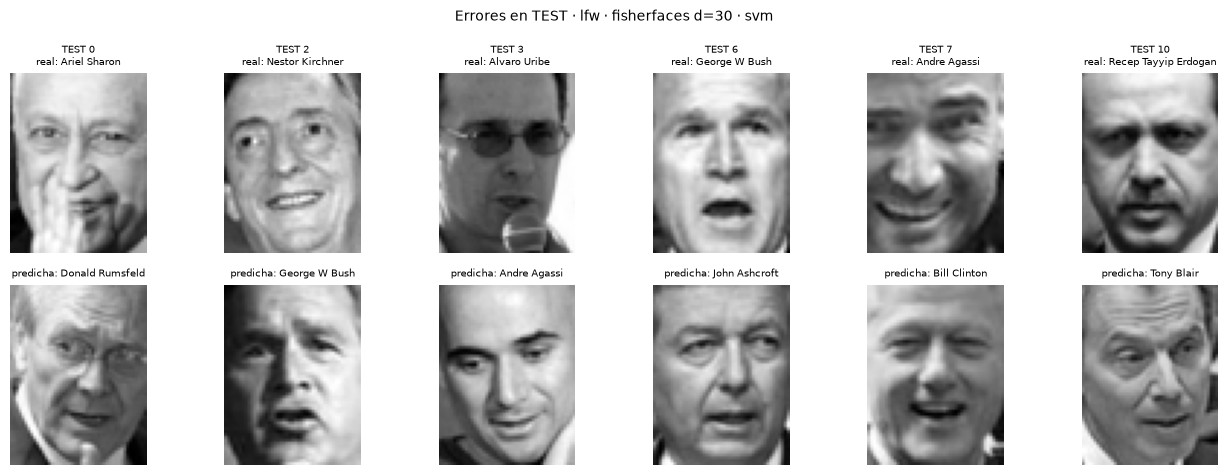

In [4]:
import matplotlib.pyplot as plt
from src.datos.division import DivisorEstratificado

predicciones = {nombre: pd.read_csv(f"data/resultados/predicciones_{nombre}.csv") for nombre in ("olivetti", "lfw")}
conjuntos = {"olivetti": olivetti, "lfw": lfw}


def mostrar_errores(dataset, embedding, d, modelo, cantidad=6):
    conjunto = conjuntos[dataset]
    particion = DivisorEstratificado().dividir(conjunto)
    tabla = predicciones[dataset]
    errores = tabla[
        (tabla["embedding"] == embedding) & (tabla["d"] == d) & (tabla["modelo"] == modelo) & ~tabla["acierto"]
    ].head(cantidad)
    fig, ejes = plt.subplots(2, len(errores), figsize=(2.2 * len(errores), 4.8), squeeze=False)
    for columna, (_, fila) in enumerate(errores.iterrows()):
        # Una foto de TRAIN de la identidad predicha, para comparar con la de TEST.
        ejemplo = particion.images_train[particion.y_train == fila["y_pred"]][0]
        ejes[0, columna].imshow(conjunto.images[fila["indice_original"]], cmap="gray")
        ejes[0, columna].set_title(f"TEST {fila['indice_test']}\nreal: {fila['nombre_real']}", fontsize=7)
        ejes[1, columna].imshow(ejemplo, cmap="gray")
        ejes[1, columna].set_title(f"predicha: {fila['nombre_pred']}", fontsize=7)
    for ax in ejes.ravel():
        ax.axis("off")
    fig.suptitle(f"Errores en TEST · {dataset} · {embedding} d={d} · {modelo}", fontsize=10)
    fig.tight_layout()
    fig.savefig(f"figuras/errores_{dataset}_{embedding}_{modelo}_d{d}.png", dpi=120)
    plt.show()


mostrar_errores("olivetti", "fisherfaces", 20, "svm")
mostrar_errores("lfw", "fisherfaces", 30, "svm")

## Robustez entre semillas (42 a 46)

In [5]:
rob = pd.read_csv("data/resultados/robustez_resumen.csv")
rob = rob[rob["d"] == 30].copy()
rob["macro_f1"] = rob["macro_f1_media"].map("{:.3f}".format) + " ± " + rob["macro_f1_std"].map("{:.3f}".format)

print("--- MACRO-F1 MEDIO ± DESVIACIÓN (5 semillas, d=30) ---")
display(rob.pivot_table(index="embedding", columns=["dataset", "modelo"], values="macro_f1", aggfunc="first"))

--- MACRO-F1 MEDIO ± DESVIACIÓN (5 semillas, d=30) ---


dataset                       lfw                                \
modelo                      arbol            knn            svm   
embedding                                                         
fisherfaces         0.182 ± 0.017  0.310 ± 0.015  0.397 ± 0.008   
fisherfaces_nc      0.026 ± 0.007  0.031 ± 0.005  0.031 ± 0.005   
fisherfaces_pca100  0.201 ± 0.023  0.481 ± 0.009  0.530 ± 0.003   
lda                 0.044 ± 0.009  0.160 ± 0.011  0.164 ± 0.015   
pca                 0.081 ± 0.013  0.167 ± 0.018  0.384 ± 0.022   

dataset                  olivetti                                
modelo                      arbol            knn            svm  
embedding                                                        
fisherfaces         0.271 ± 0.069  0.970 ± 0.022  0.974 ± 0.013  
fisherfaces_nc      0.068 ± 0.038  0.436 ± 0.175  0.438 ± 0.176  
fisherfaces_pca100  0.145 ± 0.029  0.981 ± 0.016  0.979 ± 0.018  
lda                 0.221 ± 0.049  0.978 ± 0.017  0.973 ± 0.015  
pca                 0.353 ± 0.058  0.828 ± 0.025  0.969 ± 0.021

## Análisis extendido
Iluminación simulada y oclusión en Olivetti; identidades desconocidas y barrido de d_PCA en LFW.

--- BARRIDO DE d_PCA EN FISHERFACES (media de 5 semillas) ---


accuracy_train  accuracy_test  macro_f1_test
dataset  d_pca                                              
lfw      30              0.887          0.494          0.397
         50              0.941          0.563          0.491
         100             0.970          0.606          0.530
         200             0.983          0.608          0.519
         500             0.998          0.546          0.450
         1000            1.000          0.443          0.323
         2029            1.000          0.038          0.031
olivetti 30              1.000          0.976          0.974
         50              1.000          0.978          0.978
         100             1.000          0.982          0.979
         200             1.000          0.978          0.977
         260             1.000          0.456          0.438

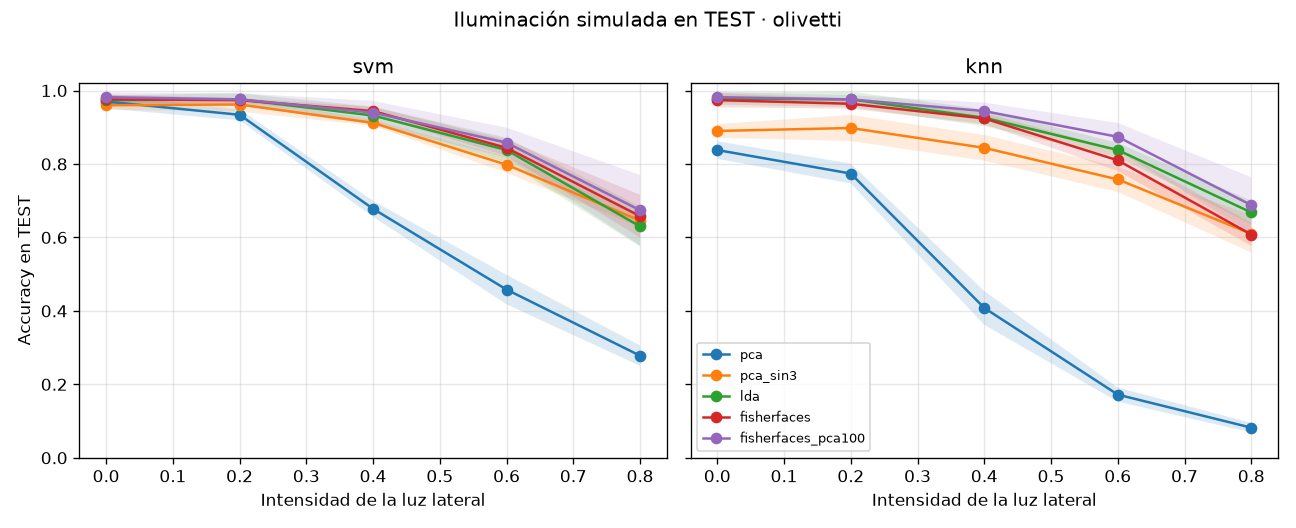

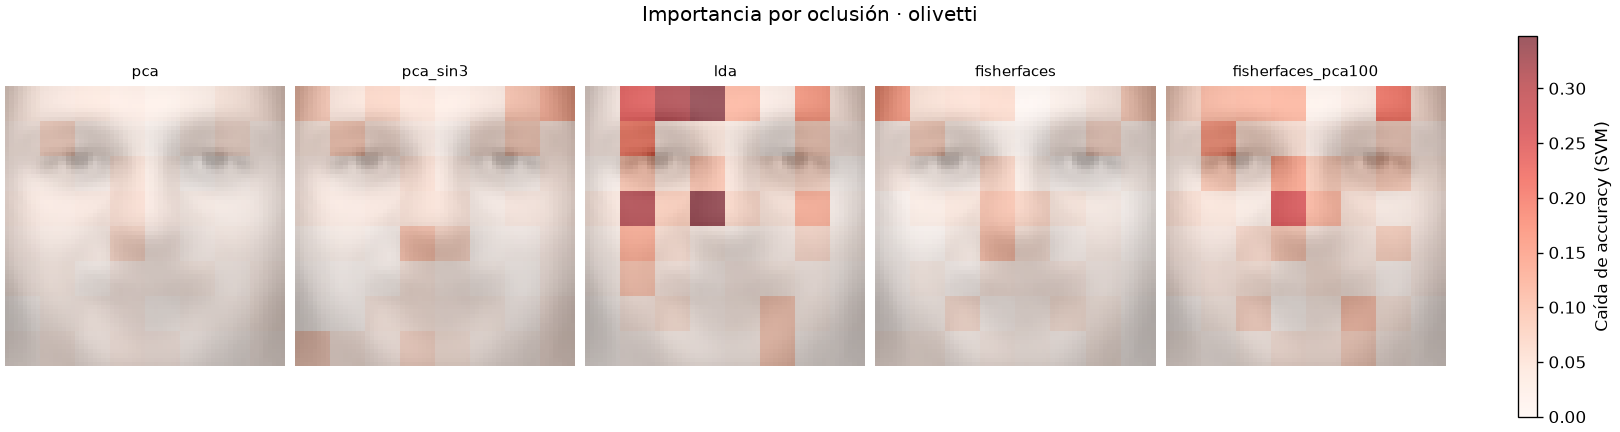

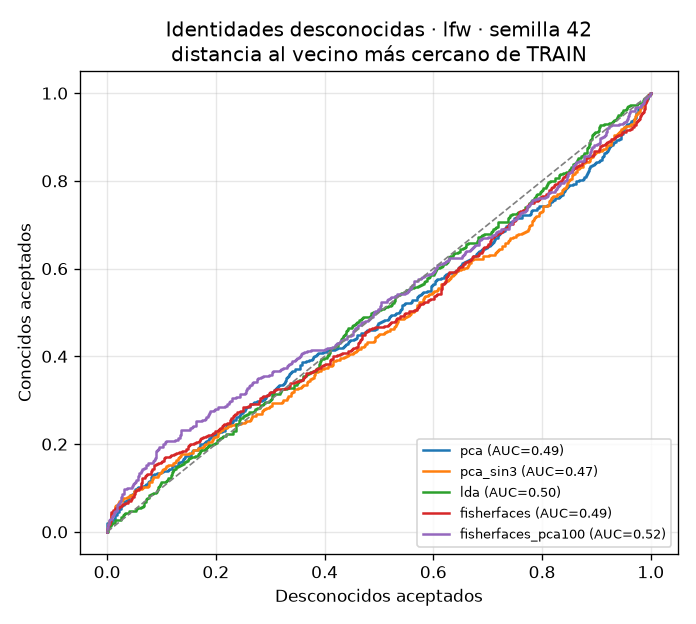

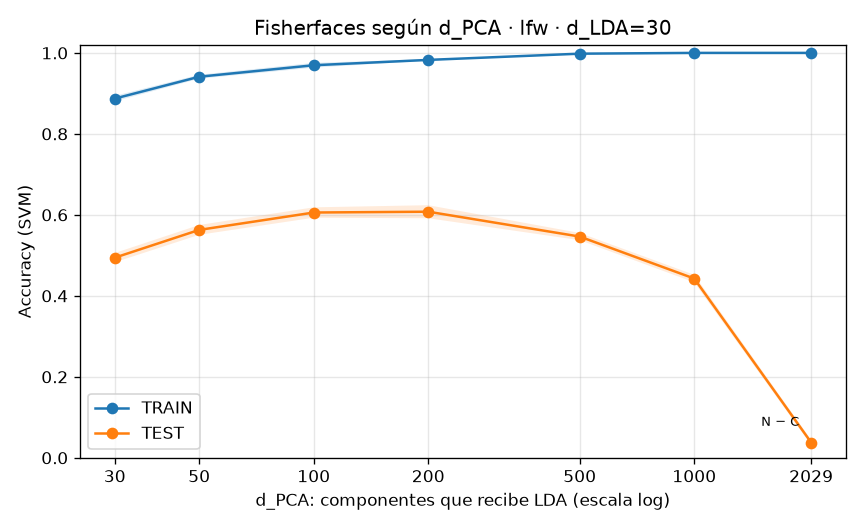

In [6]:
barrido = pd.read_csv("data/resultados/extras_barrido_dpca.csv")

print("--- BARRIDO DE d_PCA EN FISHERFACES (media de 5 semillas) ---")
display(barrido.groupby(["dataset", "d_pca"])[["accuracy_train", "accuracy_test", "macro_f1_test"]].mean().round(3))

for nombre in ("iluminacion_olivetti", "oclusion_olivetti", "desconocidos_lfw", "barrido_dpca_lfw"):
    display(Image(filename=f"figuras/extras_{nombre}.png", width=700))